# Part 3 — Decision Tree Classification

**Project:** Social Media and Stress Patterns
**Goal:** build a flowchart of simple questions that guesses a person's stress class (Low / Moderate / High) from their habits.

Design choices:
- **Target:** 3 classes — Low (≤4), Moderate (5–7), High (≥8)
- **Dataset:** the augmented modelling set — 1500 rows (500 real + 1000 synthetic) from `data/processed/social_media_stress_augmented.csv`
- **Split:** 80% training / 20% testing with a fixed seed (as required by the instructor)
- **Features:** habits only — `happiness_index` excluded (circular, it is another wellbeing score) and `screen_time_group` excluded (derived)
- **Encoding:** one-hot encoding for gender & platform
- **Model:** a single decision tree — entropy criterion, depth 5

This notebook runs `scripts/decision_tree.py` and shows the charts inline.

In [1]:
from pathlib import Path

root = Path.cwd().resolve()
if not (root / "scripts" / "decision_tree.py").exists():
    root = root.parent

script = root / "scripts" / "decision_tree.py"
fig_dir = root / "reports" / "figures"
print("Project root:", root)

%run $script

Project root: /Users/jazmingill/social-media-stress-analysis


STARTING THE DECISION TREE
STEP 1 - Target created. Class sizes:
    Moderate: 903 users (60.2%)
    High: 451 users (30.1%)
    Low: 146 users (9.7%)
    NOTE: Low is a small class -> we will use weighted metrics.

STEP 2 - Features chosen: ['age', 'gender', 'daily_screen_time_hours', 'sleep_quality', 'days_without_social_media', 'exercise_frequency_per_week', 'social_media_platform']

STEP 3 - Split: 1200 training rows, 300 test rows (80/20).

--- Decision Tree (criterion=entropy, max_depth=5) ---
    Train accuracy : 0.7550
    Test accuracy  : 0.7267
    Precision      : 0.7496   (weighted)
    Recall         : 0.7267   (weighted)
    F1 score       : 0.7013   (weighted)

    Per-class report:
                  precision    recall  f1-score   support
    
            High       0.84      0.44      0.58        97
             Low       0.73      0.32      0.44        25
        Moderate       0.70      0.94      0.80       178
    
        accuracy                           0.73    

    saved -> reports/figures/decision_tree_tree.png
    tree rules saved -> reports/decision_tree_rules.txt

STEP 9 - Feature importance:
 Rank                             Feature  Importance
    1             daily_screen_time_hours      0.8093
    2 social_media_platform = X (Twitter)      0.0539
    3                                 age      0.0526
    4                       gender = Male      0.0346
    5    social_media_platform = LinkedIn      0.0187
    6                       sleep_quality      0.0132
    7           days_without_social_media      0.0092
    8         exercise_frequency_per_week      0.0085
    9                      gender = Other      0.0000
   10   social_media_platform = Instagram      0.0000
   11      social_media_platform = TikTok      0.0000
   12     social_media_platform = YouTube      0.0000
    saved -> reports/figures/decision_tree_importance.png

Saved result tables -> reports/decision_tree_*.csv
DECISION TREE FINISHED



### decision_tree_confusion_matrix.png


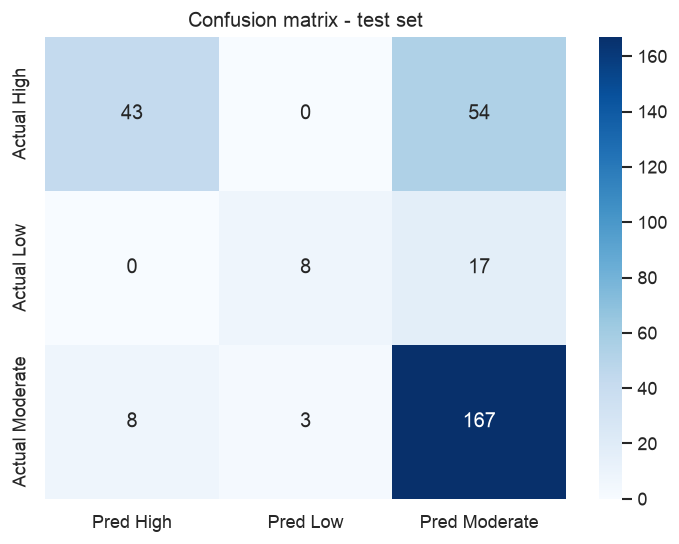


### decision_tree_tree.png


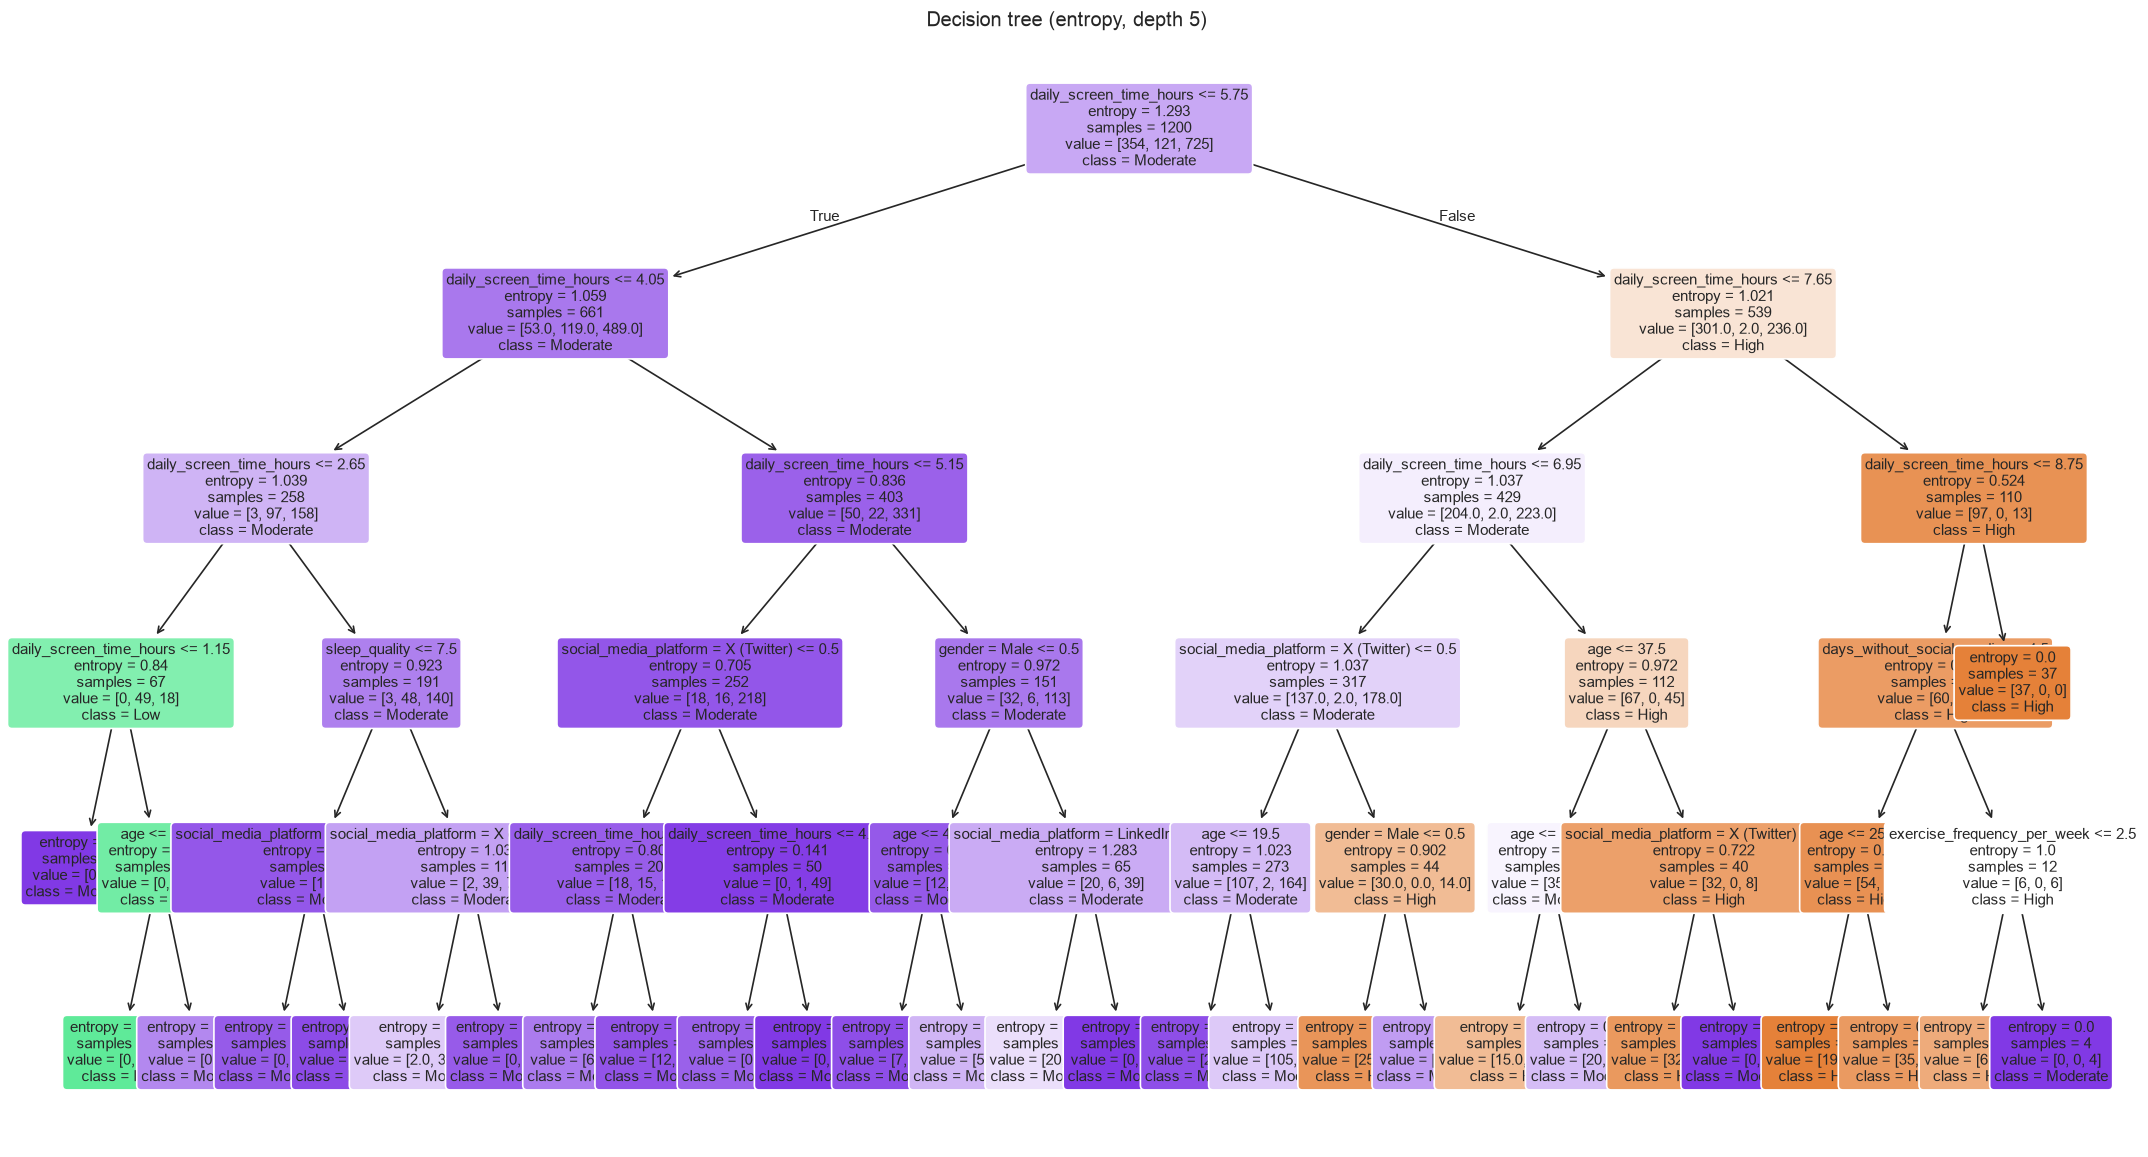


### decision_tree_importance.png


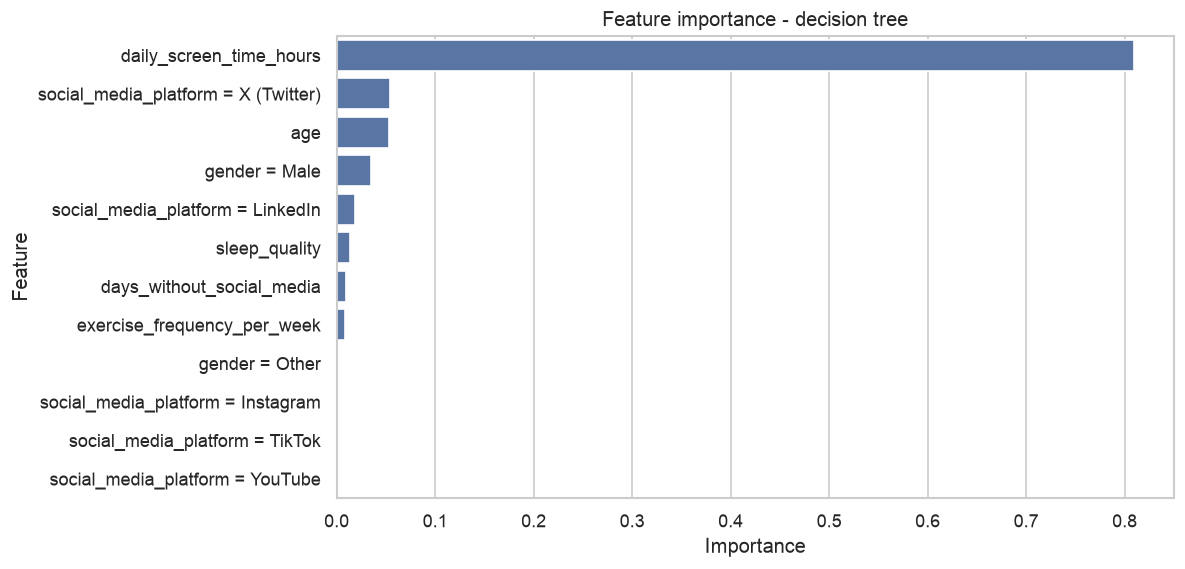

In [2]:
from IPython.display import Image, display

for name in ["decision_tree_confusion_matrix.png", "decision_tree_tree.png", "decision_tree_importance.png"]:
    print("\n###", name)
    display(Image(filename=str(fig_dir / name)))